# 3 · Evaluación de la Parte 1: comparativa y experimentos

Práctica final · **Asistente de agenda en lenguaje natural** · Procesamiento del Lenguaje Natural

Poned en la misma carpeta este notebook, `utilidades.py`, `evaluar.py`, `train.jsonl` y `agenda.jsonl`. Las celdas marcadas con `# TODO` son las que tenéis que completar.

Este notebook lee `resultados_A.json`, `resultados_B.json` y `resultados_C.json` (generados por los notebooks 2A, 2B y 2C).

In [1]:
import json, os
import pandas as pd
import matplotlib.pyplot as plt
from utilidades import cargar, guardar, particiones
from evaluar import evaluar, imprimir

train, val = particiones()
# Los notebooks 2A, 2B y 2C guardan sus resultados en resultados/
RES = {t: json.load(open(f"resultados/resultados_{t}.json", encoding="utf-8")) for t in "ABC"
       if os.path.exists(f"resultados/resultados_{t}.json")}
print("Resultados disponibles:", list(RES))

Resultados disponibles: ['A']


## Tabla comparativa
Completad las columnas que faltan (datos de entrenamiento, tamaño del modelo, ¿interpretable?).

In [2]:
def kb(b):
    return "" if b is None else f"{b / 1024:.0f} KB" if b < 2**20 else f"{b / 2**20:.1f} MB"

filas = []
for t, res in RES.items():
    for nombre, r in res.items():
        filas.append({"tarea": t, "enfoque": nombre, "métrica (validación)": r["metrica"],
                      "frases normales": r.get("normales"), "frases difíciles": r["dificiles"], "ms por frase": r["ms_por_frase"],
                      "datos de entrenamiento": r.get("datos_entrenamiento", ""), "tamaño del modelo": kb(r.get("tamano_bytes")),
                      "¿interpretable?": r.get("interpretable", "")})
tabla = pd.DataFrame(filas)
tabla.round(3)

,tarea,enfoque,métrica (validación),frases normales,frases difíciles,ms por frase,datos de entrenamiento,tamaño del modelo,¿interpretable?
0,A,A1 reglas,0.908,0.953,0.845,0.036,0,2 KB,sí
1,A,A2 BoW + Naive Bayes,0.713,0.776,0.639,0.025,308,66 KB,sí
2,A,A3 TF-IDF + RL,0.896,0.961,0.808,0.058,308,379 KB,parcial
3,A,A4 Word2Vec propio + clasificador,0.607,0.619,0.581,0.035,308,205 KB,no
4,A,A5 vectores preentrenados + clasificador,0.843,0.889,0.771,0.284,308,22.9 MB,no


## E1 · Curva de aprendizaje (tarea A)
A2, A3, A6 y A7 con 25, 50, 100 y todas las frases, al menos 3 semillas; el LLM sin entrenar (A8) como línea horizontal. Necesita `tarea_a.py` (ver notebook 2A).

In [3]:
import random, time
import numpy as np
from collections import defaultdict
from sklearn.metrics import f1_score

def submuestra(n, semilla):
    """n frases estratificadas por intención."""
    rnd = random.Random(semilla); por = defaultdict(list)
    for x in train: por[x["intencion"]].append(x)
    return [y for xs in por.values() for y in rnd.sample(xs, min(len(xs), max(1, round(n * len(xs) / len(train)))))]

ENFOQUES_E1 = ["A2", "A3"]            # fase 3: añadir "A6" y "A7" (y la línea horizontal de A8)
TAMANOS = [25, 50, 100, len(train)]
SEMILLAS = range(5)
y_val = [x["intencion"] for x in val]
try:
    from tarea_a import entrenar_y_predecir
    curva = defaultdict(dict)           # enfoque -> n -> lista de F1 (una por semilla)
    t0 = time.time()
    for enfoque in ENFOQUES_E1:
        for n in TAMANOS:
            f1s = []
            for s in SEMILLAS:
                sub = submuestra(n, s)
                pred = entrenar_y_predecir(enfoque, [x["texto"] for x in sub], [x["intencion"] for x in sub], [x["texto"] for x in val])
                f1s.append(f1_score(y_val, pred, average="macro"))
            curva[enfoque][n] = f1s
    print(f"E1 en {time.time() - t0:.0f} s")
    display(pd.DataFrame({e: {n: f"{np.mean(v):.3f} ± {np.std(v):.3f}" for n, v in d.items()} for e, d in curva.items()}))
except ImportError:
    print("Falta tarea_a.py con la función entrenar_y_predecir (ver notebook 2A)")

E1 en 1 s


,A2,A3
25,0.431 ± 0.051,0.480 ± 0.040
50,0.492 ± 0.066,0.560 ± 0.027
100,0.502 ± 0.026,0.657 ± 0.051
308,0.713 ± 0.000,0.896 ± 0.000


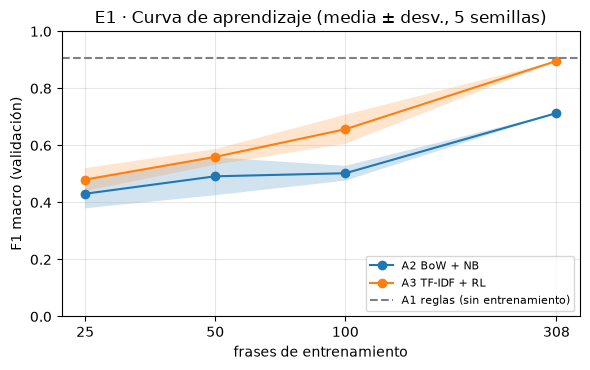

In [4]:
NOMBRES = {"A2": "A2 BoW + NB", "A3": "A3 TF-IDF + RL", "A6": "A6 embeddings + RL", "A7": "A7 embeddings + MLP"}
fig, ax = plt.subplots(figsize=(6, 3.8))
for e, d in curva.items():
    ns = sorted(d); m = np.array([np.mean(d[n]) for n in ns]); s = np.array([np.std(d[n]) for n in ns])
    ax.plot(ns, m, "o-", label=NOMBRES[e]); ax.fill_between(ns, m - s, m + s, alpha=0.2)
# Referencias sin datos de entrenamiento: las reglas (A1) y, en la fase 3, el LLM (A8)
for nombre, estilo in [("A1 reglas", "--"), ("A8 LLM few-shot", ":")]:
    if nombre in RES.get("A", {}):
        ax.axhline(RES["A"][nombre]["metrica"], ls=estilo, color="gray", label=f"{nombre} (sin entrenamiento)")
ax.set_xscale("log"); ax.minorticks_off(); ax.set_xticks(TAMANOS, [str(n) for n in TAMANOS])
ax.set_xlabel("frases de entrenamiento"); ax.set_ylabel("F1 macro (validación)"); ax.set_ylim(0, 1)
ax.set_title(f"E1 · Curva de aprendizaje (media ± desv., {len(SEMILLAS)} semillas)"); ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig("resultados/curva_aprendizaje.png", dpi=150); plt.show()

**Comentario (borrador, fase 2: A2 y A3).** Las dos curvas siguen subiendo al llegar a las 308 frases: con más datos seguirían mejorando, así que no estamos en la meseta. A3 está por encima de A2 en todos los tamaños y la distancia crece con los datos (de 0,05 con 25 frases a 0,18 con todas): los n-gramas de caracteres sacan partido de cada frase nueva, mientras que NB necesita ver cada palabra. Ninguno de los dos alcanza a las reglas (línea discontinua, sin datos de entrenamiento): A3 se queda a 0,012 con todo el corpus. Con 25 frases (unas 3 por intención), ambos están por debajo de 0,5. *Fase 3: añadir A6, A7 y la línea de A8.*

## E2 · Ablación del preprocesado
A2, A3 y A6 con texto original, normalizado, sin stopwords y con stemming (usad `normalizar` de `utilidades.py`).

In [5]:
from tarea_a import PREPRO
ENFOQUES_E2 = ["A2", "A3"]            # fase 3: añadir "A6"
CONFIGS_E2 = ["original", "normalizado", "sin_stopwords", "stemming"]
dificil = [x["dificil"] for x in val]
filas = {}
for cfg in CONFIGS_E2:
    for e in ENFOQUES_E2:
        pred = entrenar_y_predecir(e, [x["texto"] for x in train], [x["intencion"] for x in train], [x["texto"] for x in val], prepro=cfg)
        filas[(cfg, e)] = {"todas": f1_score(y_val, pred, average="macro"),
                           "difíciles": f1_score([y for y, d in zip(y_val, dificil) if d], [p for p, d in zip(pred, dificil) if d], average="macro")}
ablacion = pd.DataFrame(filas).T.unstack()
ablacion.index.name = "preprocesado"
ablacion = ablacion.loc[CONFIGS_E2]
ablacion.round(3).to_csv("resultados/ablacion_E2.csv")
for cfg in CONFIGS_E2:
    print(f"{cfg:<14} {PREPRO[cfg]}")
ablacion.round(3)

original       {'minusculas': False}
normalizado    {'quitar_tildes': True, 'abreviaturas': True, 'numeros': True}
sin_stopwords  {'quitar_tildes': True, 'abreviaturas': True, 'numeros': True, 'quitar_stopwords': True}
stemming       {'quitar_tildes': True, 'abreviaturas': True, 'numeros': True, 'quitar_stopwords': True, 'raiz': 'stem'}


todas        difíciles       
                  A2     A3        A2     A3
preprocesado                                
original       0.700  0.841     0.512  0.802
normalizado    0.713  0.896     0.639  0.808
sin_stopwords  0.611  0.795     0.549  0.834
stemming       0.576  0.805     0.494  0.834

**Comentario (borrador, fase 2: A2 y A3).** La normalización (minúsculas, tildes, abreviaturas y números) es la mejor configuración para los dos modelos de conteo: une variantes de la misma palabra (*mñn/mañana*, *QUÉ/qué*) y reduce la dispersión, sobre todo en las frases difíciles de A2 (+0,13). Quitar stopwords **perjudica** (−0,10 en A2 y A3): la lista de spaCy, incluso conservando *no, ya, qué, cuándo*, quita palabras como *lo, me, he, se, al* o *para*, que separan clases («lo de…» en `borrar`/`modificar`, «he pagado» en `completar`). El stemming no recupera lo perdido. Curiosamente, en las frases difíciles A3 mejora sin stopwords (0,834 frente a 0,808): son frases más largas y ruidosas, y quitar relleno ayuda; pero con 31 frases la diferencia es de una o dos frases. *Fase 3: añadir A6 (se espera que el preprocesado le perjudique).*

## E3 · Robustez
Cada enfoque en frases normales y difíciles. Construid un subconjunto difícil de al menos 30 frases en validación.

In [6]:
print("Frases difíciles en validación:", sum(x["dificil"] for x in val))
# La columna «frases difíciles» de la tabla comparativa ya la calcula evaluar(val, preds, "dificil")
# TODO: comparar normales frente a difíciles y comentarlo

Frases difíciles en validación: 31


## E4 · Análisis de errores
Al menos 10 errores por familia (reglas, clásicos, embeddings, Transformers, LLM), agrupados por causa, y una mejora para la causa más frecuente.

In [7]:
def errores_A(nombre, n=10):
    P = {p["id"]: p["intencion"] for p in RES["A"][nombre]["preds"]}
    return pd.DataFrame([(x["texto"], x["intencion"], P[x["id"]]) for x in val if P.get(x["id"]) != x["intencion"]][:n],
                        columns=["frase", "oro", "predicción"])
if RES.get("A"):
    print(errores_A(next(iter(RES["A"]))))
# TODO: lo mismo para B y C, y agrupar por causa

                                               frase           oro  \
0  Tengo que terminar el resumen del tema 5 de PL...   crear_tarea   
1             Mándale las fotos a papá cuando puedas   crear_tarea   
2                     Fuera lo del basket del martes        borrar   
3  Mañana como con mi padre a la una y media en e...  crear_evento   
4            Matrícula pagada, quítala de pendientes     completar   
5           Lo de los dientes pásalo a pasado mañana     modificar   
6  Ya no tengo que mandar el currículum, lo mandé...     completar   

    predicción  
0    consultar  
1       buscar  
2         otro  
3         otro  
4       borrar  
5         otro  
6  crear_tarea  


## Función para el test oculto (se entrega)
El profesor ejecutará `generar_predicciones` con el **test oculto**, que no veréis: un fichero con el mismo formato que `train.jsonl` pero sin etiquetas. Usa los enfoques elegidos que habéis exportado a `tarea_a.py`, `tarea_b.py` y `tarea_c.py`. Comprobad aquí que funciona con vuestra validación.

In [8]:
def generar_predicciones(ruta_textos, ruta_salida):
    from tarea_a import predecir_intencion
    from tarea_b import extraer_entidades
    from tarea_c import ranking_agenda
    agenda = cargar("agenda.jsonl")
    preds = [{"id": x["id"],
              "intencion": predecir_intencion(x["texto"]),
              "entidades": extraer_entidades(x["texto"]),
              "ref_ranking": ranking_agenda(x["texto"], agenda)}
             for x in cargar(ruta_textos)]
    guardar(preds, ruta_salida)
    return preds

# Comprobación con vuestra validación: el profesor hará lo mismo con el test oculto
try:
    pred = generar_predicciones("mi_validacion.jsonl", "pred_validacion.jsonl")
    imprimir(evaluar(val, pred), "Sistema completo · validación")
except ImportError as e:
    print("Faltan tarea_a.py, tarea_b.py o tarea_c.py (ver los notebooks 2A, 2B y 2C):", e)

Faltan tarea_a.py, tarea_b.py o tarea_c.py (ver los notebooks 2A, 2B y 2C): No module named 'tarea_b'
